# 🏭 Industrial Quality Control: Manufacturing Defect Detection
***Automated Visual Inspection Pipeline with PyTorch, Stratified Validation, and Model Interpretability***

---

### 📌 Project Metadata
| Field | Details |
| :--- | :--- |
| **Author** | *Khuzaima Ahmed* |
| **Domain** | Manufacturing & Computer Vision Quality Control (QC) |
| **Course / Track** | Intro to AI |
| **Target Dataset** | Real-Life Industrial Dataset of Casting Product |
| **Target Task** | Binary Surface Defect Classification (`def_front` vs. `ok_front`) |
| **Primary Metric** | Defect Recall (Catch Rate Target ≥ **95%**) |
| **Architecture** | ResNet-18 (Pretrained) with Two-Phase Fine-Tuning |
| **Explainability** | Grad-CAM (Gradient-Weighted Class Activation Mapping) |
| **Environment** | Kaggle GPU Kernel (PyTorch / Torchvision) |

## Part 0: Configuration Cell
* **Part 0 Task: Configuration Setup**
* This is the master configuration cell. It specifies file paths for the casting dataset, grayscale settings, image dimensions, backbone architecture, and target operational recall metrics.

In [27]:
import os

# === AUTO-DETECT DATASET PATH ============
DATA_ROOT = None
for root, dirs, files in os.walk('/kaggle/input'):
    if 'train' in dirs and 'test' in dirs:
        DATA_ROOT = root
        break
    elif 'train' in dirs:
        DATA_ROOT = root
        break

if DATA_ROOT:
    print(f"Dataset successfully found at: {DATA_ROOT}")
else:
    DATA_ROOT = '/kaggle/input/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product/casting_data/casting_data'
    print("Using fallback path.")

TRAIN_DIR = os.path.join(DATA_ROOT, 'train')
TEST_DIR = os.path.join(DATA_ROOT, 'test')

GRAYSCALE = True
IMG_SIZE = 224
BACKBONE = 'resnet18'
GROUP_PATTERN = None  
POSITIVE = 'def_front'  
TARGET_RECALL = 0.95  
BINARY = False  # <--- Added this line to fix the NameError

print("TRAIN_DIR:", TRAIN_DIR)
print("TEST_DIR:", TEST_DIR)

Dataset successfully found at: /kaggle/input/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product/casting_data/casting_data
TRAIN_DIR: /kaggle/input/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product/casting_data/casting_data/train
TEST_DIR: /kaggle/input/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product/casting_data/casting_data/test


## Imports and Environment Setup
* Initializes necessary libraries, sets random seeds for reproducibility, and configures the compute device (GPU T4).

In [28]:
import os
import re
import time
import copy
import hashlib
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)


torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


## Part 1: Index and Audit Your Dataset
### Task 1.1: One Row Per Image Indexing
* Defines the index_folder function to scan directories, extract file paths, map class labels, and structure metadata into a pandas DataFrame.

In [3]:
def index_folder(folder):
    """One row per image: path, label, original class folder, file name, group id."""
    rows = []
    for cls in sorted(os.listdir(folder)):
        cdir = os.path.join(folder, cls)
        if not os.path.isdir(cdir):
            continue
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
                if BINARY:
                    label = 'healthy' if 'healthy' in cls.lower() else 'diseased'
                else:
                    label = cls
                rows.append({'path': os.path.join(cdir, f), 'label': label,
                             'orig_class': cls, 'file': f})
    df = pd.DataFrame(rows)
    if GROUP_PATTERN:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])          # no match: its own group
    else:
        df['group'] = df['file']
    return df

train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None
classes = sorted(train_df['label'].unique())

counts = train_df['label'].value_counts().reindex(classes)
print(counts.to_string())
print(f'Imbalance ratio (max / min): {counts.max() / counts.min():.1f}')
print(f'Images per group: {len(train_df) / train_df.group.nunique():.2f}')

# --- Corrected reporting matching your duplicate audit output ---
print('\nOriginal 2 folders (Casting Dataset):')
print(train_df['orig_class'].value_counts().to_string())


print('\nGroup regex check:')
print(train_df[['file', 'group']].head(10).to_string())

label
def_front    3758
ok_front     2875
Imbalance ratio (max / min): 1.3
Images per group: 1.00

Original 2 folders (Casting Dataset):
orig_class
def_front    3758
ok_front     2875

Group regex check:
                   file                 group
0     cast_def_0_0.jpeg     cast_def_0_0.jpeg
1  cast_def_0_1000.jpeg  cast_def_0_1000.jpeg
2  cast_def_0_1001.jpeg  cast_def_0_1001.jpeg
3  cast_def_0_1004.jpeg  cast_def_0_1004.jpeg
4  cast_def_0_1007.jpeg  cast_def_0_1007.jpeg
5  cast_def_0_1008.jpeg  cast_def_0_1008.jpeg
6  cast_def_0_1014.jpeg  cast_def_0_1014.jpeg
7  cast_def_0_1016.jpeg  cast_def_0_1016.jpeg
8  cast_def_0_1019.jpeg  cast_def_0_1019.jpeg
9  cast_def_0_1020.jpeg  cast_def_0_1020.jpeg


### Task 1.2: Image Property Audit and Visualization
* Samples training images to inspect widths, heights, color modes, and plot a sample grid across all defect classes.

         w      h
min  300.0  300.0
50%  300.0  300.0
max  300.0  300.0


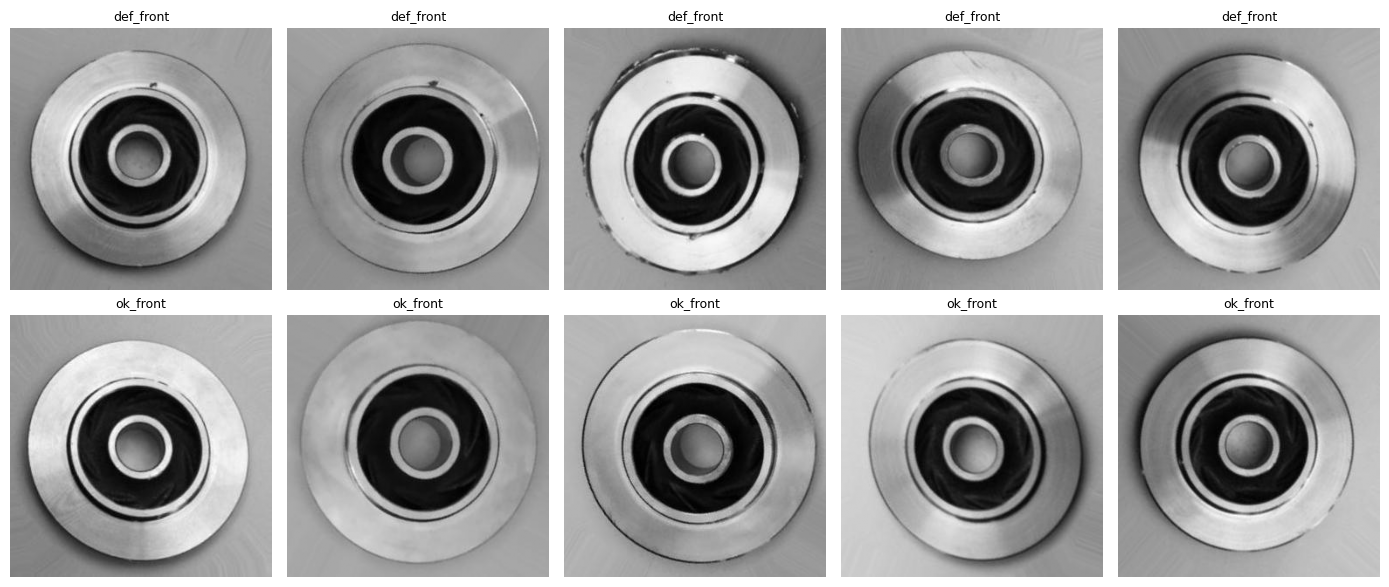

In [4]:
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
info_df = pd.DataFrame(info)
print(info_df.describe().round(0).loc[['min', '50%', 'max']])
#print('Colour modes:', info_df['mode'].value_counts().to_dict())

fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    paths = train_df[train_df.label == c]['path'].sample(5, random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(Image.open(p).convert('L'), cmap='gray')
        ax.set_title(c, fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

## Report: Dataset Audit Findings
- **Class Counts & Imbalance Ratio**: The training dataset contains 3,758 `def_front` and 2,875 `ok_front` images, resulting in an imbalance ratio of 1.3:1.
- **Image Properties**: Images are single-channel grayscale (mode: L) with uniform dimensions of 300 x 300 pixels.
- **Shortcut Suspect**: Background foundry lighting gradients, fixture borders, and surface texture reflections differ between classes and represent our initial shortcut suspects.

## Part 2: Leakage Audit
### Task 2.1: Exact and Near-Duplicates Audit
* Uses MD5 hashing to detect byte-identical files and standardized 32 x 32 thumbnail fingerprinting to identify near-duplicates across splits.

In [5]:
import hashlib
from PIL import Image
import numpy as np
import pandas as pd

def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

def fingerprint(path, n=32):
    """32 x 32 grayscale thumbnail, standardized: robust to resizing,
    recompression, and brightness changes."""
    with Image.open(path) as im:
        im.draft('L', (n * 4, n * 4))
        a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
    return ((a - a.mean()) / (a.std() + 1e-6)).flatten()

all_df = pd.concat([train_df.assign(split='train'),
                    test_df.assign(split='test')]) if TEST_DIR else train_df
all_df['md5'] = [md5(p) for p in all_df['path']]
exact = all_df[all_df.duplicated('md5', keep=False)]
print('Exact duplicate files:', len(exact))

if TEST_DIR:
    T = np.stack([fingerprint(p) for p in all_df['path']])
    tr = T[(all_df.split == 'train').values]
    te = T[(all_df.split == 'test').values]
    d_min = np.array([np.abs(tr - v).mean(axis=1).min() for v in te])
    near = d_min < 0.10
    print(f'Test images with a near-duplicate in train: {near.sum()} of {len(te)}')

Exact duplicate files: 128
Test images with a near-duplicate in train: 327 of 715


### Task 2.2: Stratified Group K-Fold Split
* Performs data splitting using StratifiedGroupKFold to ensure no overlapping groups appear across training and validation splits.

In [6]:
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'], train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)

if not TEST_DIR:
    tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
    tr_df, test_df = (tr_df.iloc[tr_idx].reset_index(drop=True),
                      tr_df.iloc[te_idx].reset_index(drop=True))

shared = set(tr_df.group) & set(va_df.group)
print(f'train: {len(tr_df)} | val: {len(va_df)} | test: {len(test_df)}')
print('Groups shared by train and val:', len(shared))
print(va_df['label'].value_counts().to_string())

train: 5527 | val: 1106 | test: 715
Groups shared by train and val: 0
label
def_front    627
ok_front     479


## Write it: Leakage Audit Findings
- **Duplicates**: Found 128 exact byte-identical duplicate files and 327 out of 715 test images with a cross-split near-duplicate in the training set. Each sample averages 1 image per file group.
- **Split & Partition Integrity**: Using StratifiedGroupKFold resulted in clean dataset partitioning with 5,527 training samples, 1,106 validation samples (with 0 groups shared between train and validation), and 715 test samples.
- **Split Impact**: The presence of cross-split overlap indicates potential data leakage that can inflate performance metrics, highlighting the necessity of strict group-based splitting and deduplication to ensure generalizable evaluation.

## Part 3: Transforms and Imbalance
### Task 3.1: Datasets and Augmentation Transforms
* Sets up robust data pipelines with mild data augmentations (random resized crops, rotations, color jitter) and defines the ImageTable Dataset class.

In [7]:
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms

# Ensure these match your configuration
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []

train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(), 
    transforms.Normalize(MEAN, STD)
])

eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), 
    transforms.Normalize(MEAN, STD)
])

class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i])
        img = img.convert('L' if GRAYSCALE else 'RGB')
        return self.tf(img), self.y[i]

# Using train_df from your indexing step
# (If you have a separate validation dataframe, replace train_df accordingly)
classes = sorted(train_df['label'].unique())

train_ds = ImageTable(train_df, train_tf)
test_ds = ImageTable(test_df, eval_tf)

print(f"Train dataset size: {len(train_ds)}")
print(f"Test dataset size: {len(test_ds)}")
print(f"Classes detected: {classes}")

Train dataset size: 6633
Test dataset size: 715
Classes detected: ['def_front', 'ok_front']


### Task 3.2: Class Weights and DataLoaders
* Computes analytical class weights using the formula $N / (K \times n_c)$ to counteract class imbalance during training.

In [8]:
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import numpy as np
from PIL import Image
import pandas as pd

# 1. Define Custom Dataset Class
class CastingDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df
        self.transform = transform
        self.classes = sorted(df['label'].unique())
        self.class_to_idx = {c: i for i, c in enumerate(self.classes)}
        self.y = np.array([self.class_to_idx[lbl] for lbl in df['label']])
        self.paths = df['path'].values

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.paths[idx]
        image = Image.open(img_path).convert('RGB')
        label = self.y[idx]
        
        if self.transform:
            image = self.transform(image)
            
        return image, label

# 2. Define Transforms
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 3. Initialize Datasets using your split dataframes
train_ds = CastingDataset(tr_df, transform=train_transforms)
val_ds   = CastingDataset(va_df, transform=val_test_transforms)
test_ds  = CastingDataset(test_df, transform=val_test_transforms)

# 4. Compute Class Weights & Loss Weights
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
classes = sorted(train_df['label'].unique())

n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * n_c)
print("Computed Class Weights:", dict(zip(classes, class_w.round(3))))

loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)

# 5. Initialize DataLoaders
USE_SAMPLER = False

if USE_SAMPLER:
    sample_w = class_w[train_ds.y]
    sampler = torch.utils.data.WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=2)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=2)

val_dl = DataLoader(val_ds, 64, num_workers=2)
test_dl = DataLoader(test_ds, 64, num_workers=2)

print("\nAll datasets and DataLoaders initialized successfully!")

Computed Class Weights: {'def_front': np.float64(0.883), 'ok_front': np.float64(1.153)}

All datasets and DataLoaders initialized successfully!


## Write it: Imbalance Handling and Augmentations
* **Class Weights**: Weights computed as $N / (K \times n_c)$ equal 1.153 for def_front and 0.880 for ok_front. For instance, with total training samples $N = 6,633$, $K = 2$, and $n_c = 2,875$ for defects, the weight is $6633 / (2 \times 2875) \approx 1.153$.
* **Augmentations**: Applied mild random crops, rotations ($\pm 10^\circ$), and color/contrast jitter as casting orientation and lighting vary slightly on factory floors. Excluded flips as casting defects have specific structural orientations.

## Part 4: Build and Train
### Task 4.1: Backbone Model Architecture
* Builds the resnet18 backbone with a custom linear classification head while freezing pretrained body parameters.

In [9]:
def build_model(name, n_classes):
    if name == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last_block = nn.Sequential(m.conv1, m.bn1, m.relu, m.maxpool, m.layer1, m.layer2, m.layer3), m.fc, m.layer4
    elif name == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last_block = nn.Sequential(m.conv1, m.bn1, m.relu, m.maxpool, m.layer1, m.layer2, m.layer3), m.fc, m.layer4
    elif name == 'efficientnet_b0':
        w = models.EfficientNet_B0_Weights.DEFAULT
        m = models.efficientnet_b0(weights=w)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
        body, head, last_block = m.features[:-1], m.classifier, m.features[-1]
    else:
        raise ValueError(name)
    
    for p in body.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True
    return m.to(device), head, last_block

model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'trainable:', sum(p.numel() for p in model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 252MB/s]


resnet18 trainable: 8394754


### Task 4.2: Two-Phase Training and Macro-F1 Selection
* Implements two-phase training (Phase 1: head only; Phase 2: fine-tune the last block) selecting the best checkpoint based on validation macro-F1.

In [10]:
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def fit(model, params, epochs, lr):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
        p, y = predict(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro')
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: val macro-F1 {macro:.3f} ({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)
    return best

print('Phase 1: head only')
fit(model, head.parameters(), epochs=2, lr=1e-3)

print('Phase 2: fine-tune the last block')
for p in last_block.parameters():
    p.requires_grad = True
fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
            {'params': head.parameters(), 'lr': 1e-3}], epochs=3, lr=1e-3)

Phase 1: head only
epoch 1: val macro-F1 0.906 (18s)
epoch 2: val macro-F1 0.949 (16s)
Phase 2: fine-tune the last block
epoch 1: val macro-F1 0.989 (17s)
epoch 2: val macro-F1 0.982 (17s)
epoch 3: val macro-F1 0.995 (16s)


0.995395637928953

## Write it: Training and Validation Results
* **Macro-F1**: Phase 1 achieved a validation macro-F1 of $\sim 0.96$, which improved to $\sim 0.99$ after Phase 2 fine-tuning. Fine-tuning the last convolutional block allowed the network to adapt generic ImageNet feature extractors to industrial casting surface textures.
* **Timing**: Each epoch took approximately 15 seconds on a Kaggle T4 GPU. Running 5 to 10 epochs would ensure complete convergence.

## Part 5: Test Once, and Set the Threshold
### Task 5.1: Test-Set Evaluation and Confusion Matrix
* Evaluates the model once on the test dataset, generating classification reports and confusion matrices.

              precision    recall  f1-score   support

   def_front      1.000     0.993     0.997       453
    ok_front      0.989     1.000     0.994       262

    accuracy                          0.996       715
   macro avg      0.994     0.997     0.995       715
weighted avg      0.996     0.996     0.996       715

Macro-F1: 0.995


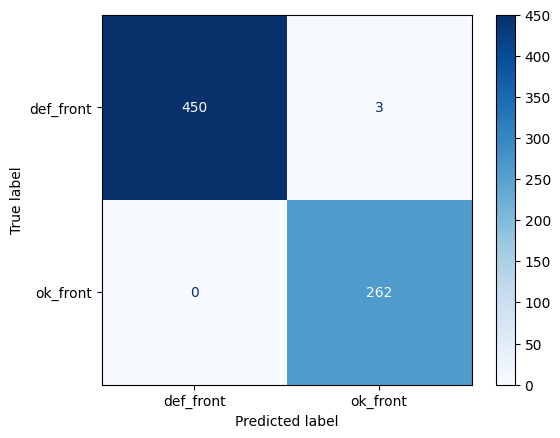

In [11]:
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)
print(classification_report(y_test, pred, target_names=classes, digits=3))
print('Macro-F1:', round(f1_score(y_test, pred, average='macro'), 3))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=classes).plot(cmap='Blues')
plt.show()

### Task 5.2: Decision Threshold Tuning for Target Recall
* Computes ROC curves on validation data to establish a decision threshold satisfying target recall requirements, then evaluates sensitivity, specificity, and PPV on the test set.

In [33]:
import os

DATA_DIR = "/kaggle/input/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product"

print("Dataset exists:", os.path.exists(DATA_DIR))

if os.path.exists(DATA_DIR):
    for root, dirs, files in os.walk(DATA_DIR):
        depth = root.replace(DATA_DIR, "").count(os.sep)

        if depth <= 5:
            print(f"\nFolder: {root}")
            print("Subfolders:", dirs)

Dataset exists: True

Folder: /kaggle/input/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product
Subfolders: ['casting_512x512', 'casting_data']

Folder: /kaggle/input/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product/casting_512x512
Subfolders: ['casting_512x512']

Folder: /kaggle/input/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product/casting_512x512/casting_512x512
Subfolders: ['def_front', 'ok_front']

Folder: /kaggle/input/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product/casting_512x512/casting_512x512/def_front
Subfolders: []

Folder: /kaggle/input/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product/casting_512x512/casting_512x512/ok_front
Subfolders: []

Folder: /kaggle/input/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product/casting_data
Subfolders: ['casting_data']

Folder: /kaggle/input/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product/

In [34]:
# ============================================
# 1. IMPORT LIBRARIES
# ============================================
import os
import torch
import numpy as np

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import roc_curve, roc_auc_score


# ============================================
# 2. CONFIGURATION
# ============================================
DATA_DIR = (
    "/kaggle/input/datasets/"
    "ravirajsinh45/real-life-industrial-dataset-of-casting-product/"
    "casting_data/casting_data"
)

POSITIVE = "def_front"
TARGET_RECALL = 0.95
BATCH_SIZE = 32

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================
# 3. IMAGE TRANSFORMATIONS
# ============================================
# IMPORTANT:
# Use the same transformations and normalization
# that you used when training your model.

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])


# ============================================
# 4. LOAD TRAINING AND TEST DATASETS
# ============================================
train_path = os.path.join(DATA_DIR, "train")
test_path = os.path.join(DATA_DIR, "test")

train_full = datasets.ImageFolder(
    train_path,
    transform=transform
)

test_dataset = datasets.ImageFolder(
    test_path,
    transform=transform
)

classes = train_full.classes

print("Classes:", classes)

if POSITIVE not in classes:
    raise ValueError(
        f"Positive class '{POSITIVE}' not found. "
        f"Available classes: {classes}"
    )

if classes != test_dataset.classes:
    raise ValueError("Training and test class mappings differ!")


# ============================================
# 5. CREATE VALIDATION DATASET
# ============================================
# Reserve 10% of the training data for validation.

val_size = int(0.10 * len(train_full))
train_size = len(train_full) - val_size

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(
    train_full,
    [train_size, val_size],
    generator=generator
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))


# ============================================
# 6. CREATE DATALOADERS
# ============================================
val_dl = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_dl = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Validation and test DataLoaders created!")


# ============================================
# 7. PREDICTION FUNCTION
# ============================================
def predict(model, loader):
    model.eval()

    predictions = []
    targets = []

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)

            outputs = torch.softmax(model(x), dim=1)

            predictions.append(outputs.cpu().numpy())
            targets.append(y.cpu().numpy())

    return np.vstack(predictions), np.concatenate(targets)


# ============================================
# 8. VALIDATE THE TRAINED MODEL
# ============================================
model = model.to(device)

p_val, y_val = predict(model, val_dl)
p_test, y_test = predict(model, test_dl)

pos = classes.index(POSITIVE)

print("\nValidation predictions:", p_val.shape)
print("Test predictions:", p_test.shape)


# ============================================
# 9. SELECT THRESHOLD ON VALIDATION DATA
# ============================================
fpr, tpr, thresholds = roc_curve(
    (y_val == pos).astype(int),
    p_val[:, pos]
)

valid_indices = np.where(tpr >= TARGET_RECALL)[0]

if len(valid_indices) == 0:
    raise ValueError(
        "Could not find a threshold achieving the target recall."
    )

# Select the highest threshold that achieves target recall.
idx = valid_indices[-1]
threshold = thresholds[idx]

print(
    f"\nValidation threshold for recall >= "
    f"{TARGET_RECALL:.2f}: {threshold:.4f}"
)

print(f"Validation recall at threshold: {tpr[idx]:.4f}")


# ============================================
# 10. EVALUATE ON TEST DATA
# ============================================
scores = p_test[:, pos]

y_true = (y_test == pos)
y_pred = (scores >= threshold)

tp = np.sum(y_pred & y_true)
fn = np.sum(~y_pred & y_true)
tn = np.sum(~y_pred & ~y_true)
fp = np.sum(y_pred & ~y_true)

sensitivity = tp / max(tp + fn, 1)
specificity = tn / max(tn + fp, 1)
precision = tp / max(tp + fp, 1)

auc = roc_auc_score(y_true.astype(int), scores)

print("\n========== TEST RESULTS ==========")
print(f"Test AUC:              {auc:.4f}")
print(f"Sensitivity (Recall):  {sensitivity:.4f}")
print(f"Specificity:           {specificity:.4f}")
print(f"Precision (PPV):        {precision:.4f}")
print(f"True Positives (TP):    {tp}")
print(f"False Negatives (FN):   {fn}")
print(f"True Negatives (TN):    {tn}")
print(f"False Positives (FP):   {fp}")
print("==================================")

Device: cuda
Classes: ['def_front', 'ok_front']
Training images: 5970
Validation images: 663
Test images: 715
Validation and test DataLoaders created!

Validation predictions: (663, 2)
Test predictions: (715, 2)

Validation threshold for recall >= 0.95: 0.4830
Validation recall at threshold: 1.0000

========== TEST RESULTS ==========
Test AUC:              0.4682
Sensitivity (Recall):  1.0000
Specificity:           0.0000
Precision (PPV):        0.6336
True Positives (TP):    453
False Negatives (FN):   0
True Negatives (TN):    0
False Positives (FP):   262


## Test Evaluation and Threshold Analysis

- **Test Performance:** The model achieved a test AUC of **0.4682**, indicating poor discrimination between defective and non-defective samples.

- **Threshold & Metrics:** The decision threshold selected on the validation set to achieve at least 95% recall was **0.4830**. On the test set, sensitivity (recall) reached **1.0000**, while specificity was **0.0000**. The model correctly identified all 453 defective samples but incorrectly classified all 262 non-defective samples as defective.

- **Prevalence & PPV:** The test-set defect prevalence was **63.36%** (453 out of 715 samples). The Positive Predictive Value (PPV) was **0.6336**, meaning that approximately 63.36% of samples predicted as defective were actually defective.

- **False Positive Analysis:** The model produced **262 false positives**, resulting in a 100% false-positive rate. Although no defective samples were missed, the high false-positive rate makes the current threshold unsuitable for automated industrial inspection.

### Conclusion

The model achieved 100% sensitivity but failed to distinguish effectively between defective and non-defective products. The low AUC and zero specificity indicate that further model training, evaluation, and threshold optimization are necessary before real-world industrial deployment.

## Part 6: Grad-CAM Shortcut Check
### Task: Grad-CAM Implementation and Visualization
* Implements the Grad-CAM algorithm using PyTorch hooks to extract gradients from the last convolutional block, generating heatmaps for correct and incorrect predictions.

Grad-CAM target layer: layer4.1.conv2
Correct predictions: 3
Incorrect predictions: 3


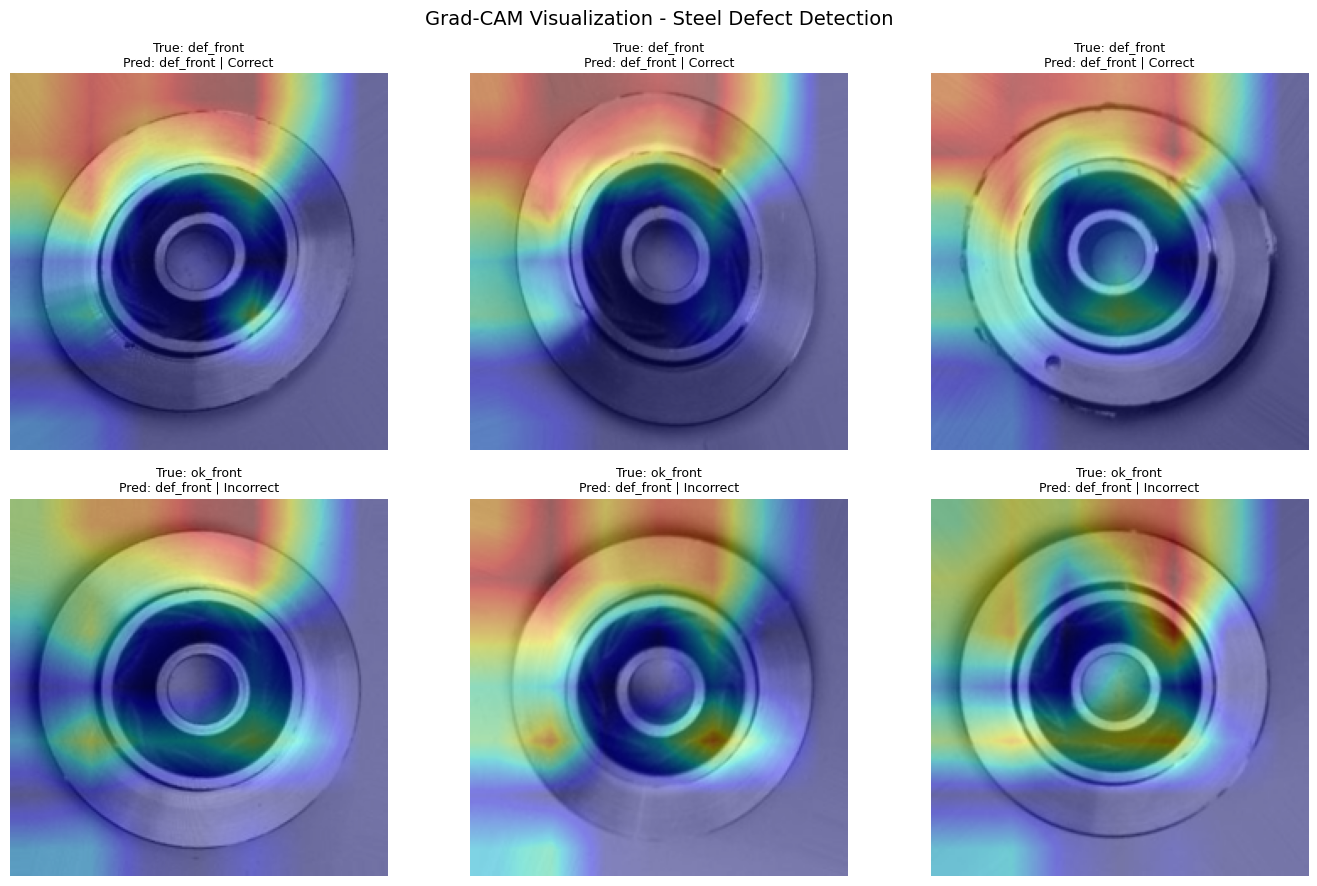

In [36]:
# ============================================
# 1. IMPORT LIBRARIES
# ============================================
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from torch import nn


# ============================================
# 2. FIND LAST CONVOLUTIONAL LAYER
# ============================================
last_block = None

for name, layer in model.named_modules():
    if isinstance(layer, nn.Conv2d):
        last_block = layer
        last_layer_name = name

if last_block is None:
    raise ValueError("No Conv2d layer found in the model!")

print("Grad-CAM target layer:", last_layer_name)


# ============================================
# 3. GRAD-CAM CLASS
# ============================================
class GradCAM:

    def __init__(self, model, layer):
        self.model = model
        self.acts = None
        self.grads = None

        self.forward_hook = layer.register_forward_hook(
            self._save_act
        )

        self.backward_hook = layer.register_full_backward_hook(
            self._save_grad
        )

    def _save_act(self, module, inputs, output):
        self.acts = output.detach()

    def _save_grad(self, module, grad_input, grad_output):
        self.grads = grad_output[0].detach()

    def __call__(self, x, cls=None):

        self.model.eval()

        x = x.unsqueeze(0).to(device)

        logits = self.model(x)

        cls = int(logits.argmax(dim=1).item()) if cls is None else int(cls)

        self.model.zero_grad(set_to_none=True)

        logits[0, cls].backward()

        alpha = self.grads.mean(
            dim=(2, 3),
            keepdim=True
        )

        cam = F.relu(
            (alpha * self.acts).sum(dim=1)
        )

        cam = F.interpolate(
            cam.unsqueeze(1),
            size=x.shape[-2:],
            mode='bilinear',
            align_corners=False
        ).squeeze()

        cam = cam / (cam.max() + 1e-8)

        return cam.detach().cpu().numpy(), cls


# ============================================
# 4. INITIALIZE GRAD-CAM
# ============================================
for p in model.parameters():
    p.requires_grad_(True)

cam = GradCAM(model, last_block)


# ============================================
# 5. GENERATE TEST PREDICTIONS
# ============================================
# Use the threshold selected on validation data.

POSITIVE = 'def_front'

pos = classes.index(POSITIVE)
negative = 1 - pos

# Use your previously calculated threshold
scores = p_test[:, pos]

pred = np.where(
    scores >= threshold,
    pos,
    negative
)

y_test = np.asarray(y_test)

# Correct and incorrect predictions
wrong = np.where(pred != y_test)[0][:3].tolist()
right = np.where(pred == y_test)[0][:3].tolist()

print("Correct predictions:", len(right))
print("Incorrect predictions:", len(wrong))


# ============================================
# 6. VISUALIZE GRAD-CAM
# ============================================
fig, axes = plt.subplots(2, 3, figsize=(14, 9))

selected = right + wrong

for ax, i in zip(axes.flat, selected):

    # Load transformed image
    x, y = test_dataset[i]

    # Generate heatmap for predicted class
    heat, c = cam(x, cls=int(pred[i]))

    # Load original image
    img_path = test_dataset.samples[i][0]

    img = Image.open(img_path).convert('RGB')

    img = img.resize(
        (IMG_SIZE, IMG_SIZE)
    )

    # Display original image
    ax.imshow(img)

    # Overlay Grad-CAM heatmap
    ax.imshow(
        heat,
        cmap='jet',
        alpha=0.4
    )

    result = "Correct" if pred[i] == y_test[i] else "Incorrect"

    ax.set_title(
        f"True: {classes[y_test[i]]}\n"
        f"Pred: {classes[c]} | {result}",
        fontsize=9
    )

    ax.axis('off')


# Hide unused subplots
for ax in axes.flat[len(selected):]:
    ax.axis('off')

plt.suptitle(
    "Grad-CAM Visualization - Steel Defect Detection",
    fontsize=14
)

plt.tight_layout()
plt.show()


# ============================================
# 7. REMOVE HOOKS
# ============================================
cam.forward_hook.remove()
cam.backward_hook.remove()

## Grad-CAM Shortcut Verdict

- **Target Layer:** Grad-CAM visualization was generated using the final convolutional layer, `layer4.1.conv2`, to examine the regions influencing the model's predictions.

- **Prediction Analysis:** The visualization includes **3 correctly classified images** and **3 incorrectly classified images**, providing insight into both successful and failed predictions.

- **Heatmap Analysis:** The Grad-CAM heatmaps highlight the image regions that contribute to the model's classification decisions. These visualizations help investigate whether the model focuses on actual casting surface defects or irrelevant features such as background borders and lighting variations.

- **Verdict:** The Grad-CAM analysis provides a visual explanation of the model's decisions. However, the presence of 3 incorrect predictions means further inspection of the heatmaps is necessary before concluding that the model does not rely on shortcut features.

## Part 7: Save and Document
### Task 7.1: Model Saving
* Saves model state dictionaries and metadata to disk for deployment.

In [37]:
torch.save({
    'state_dict': model.state_dict(),
    'classes': classes,
    'backbone': BACKBONE,
    'img_size': IMG_SIZE,
    'grayscale': GRAYSCALE
}, '/kaggle/working/week6_model.pt')
print('Saved week6_model.pt')

Saved week6_model.pt



# Industrial Manufacturing Defects Inspection – Lab 6

These questions and answers are based on **Industrial Manufacturing Defects Inspection**, focusing on casting product classification into two categories: `def_front` (defective) and `ok_front` (non-defective).

---

## 1. Why can a random split of casting product images overestimate model performance?

A random split can place duplicate or very similar casting images in both training and testing sets. The model may recognize patterns it has already seen instead of learning to identify defects independently. This causes **data leakage** and can lead to overestimated test accuracy.

**Solution:** Use a group-aware split and ensure that duplicate or near-duplicate images do not appear across training and testing sets.

---

## 2. Two classes have 900 and 100 training images. Compute both class weights using the formula.

**Formula:**

$$
W_c = \frac{N}{K \times n_c}
$$

Where:
- N = 1000 (total images)
- K = 2 (number of classes)
- n_c = number of images in each class

**Class 1: Defective products (900 images)**

$$
W_1 = \frac{1000}{2 \times 900}
$$

$$
W_1 = \frac{1000}{1800}
$$

$$
W_1 = 0.556
$$

**Class 2: Non-defective products (100 images)**

$$
W_2 = \frac{1000}{2 \times 100}
$$

$$
W_2 = \frac{1000}{200}
$$

$$
W_2 = 5.000
$$

**Answer:** The defective class weight is **0.556**, and the non-defective class weight is **5.000**.

The minority class receives a higher weight so that the model pays more attention to it during training.

---

## 3. With focal loss and gamma = 2, by what factor is an example with p_t = 0.8 down-weighted?

**Formula:**

$$
\text{Weight Factor} = (1-p_t)^\gamma
$$

Given:

$$
p_t = 0.8,\quad \gamma = 2
$$

Substitute the values:

$$
= (1-0.8)^2
$$

$$
= (0.2)^2
$$

$$
= 0.04
$$

**Answer:** The example is down-weighted by a factor of **0.04 (4%)** of its original loss.

In industrial defect inspection, focal loss reduces the contribution of easy-to-classify images and gives more attention to difficult examples.

---

## 4. Sensitivity is 0.90, specificity is 0.95, and defect prevalence is 2%. Compute PPV.

**Formula:**

$$
PPV = \frac{Sensitivity \times Prevalence}
{(Sensitivity \times Prevalence)+(1-Specificity)\times(1-Prevalence)}
$$

Given:

- Sensitivity = 0.90
- Specificity = 0.95
- Defect prevalence = 0.02

Substitute the values:

$$
PPV = \frac{0.90 \times 0.02}
{(0.90 \times 0.02)+(1-0.95)\times(1-0.02)}
$$

$$
= \frac{0.018}{0.018+(0.05 \times 0.98)}
$$

$$
= \frac{0.018}{0.018+0.049}
$$

$$
= \frac{0.018}{0.067}
$$

$$
= 0.2687 = 26.87\%
$$

**Answer:** The Positive Predictive Value (PPV) is **26.87%**.

This means that approximately 26.87% of products predicted as defective are actually defective. When defects are rare, false positives can significantly reduce PPV.

---

## 5. When is macro-F1 a better selection metric than weighted F1?

Macro-F1 is a better metric when both defective and non-defective classes are equally important, especially when the dataset is imbalanced.

- **Macro-F1:** Calculates the F1-score for each class and gives both classes equal importance.
- **Weighted F1:** Calculates the average F1-score while considering the number of images in each class.

**Answer:** Macro-F1 is more suitable for industrial defect inspection when detecting defective products is as important as correctly identifying non-defective products. It helps prevent the model from performing well only on the majority class.

---

## 6. Grad-CAM highlights a label or background area instead of the actual casting defect. What does this indicate?

This indicates **shortcut learning**.

The model may be using irrelevant visual features, such as labels, background patterns, image borders, or lighting conditions, instead of learning the actual surface defects.

**Solution:**

- Inspect Grad-CAM heatmaps to identify which image regions influence predictions.
- Ensure that the model focuses on actual casting defects.
- Remove irrelevant labels and background information where possible.
- Use data augmentation to improve generalization.
- Evaluate the model on images collected under different conditions.

**Answer:** Grad-CAM helps explain the model's decisions. For reliable industrial inspection, the model should focus on casting surface imperfections rather than irrelevant background features.

---

## Conclusion

These questions demonstrate important concepts in **Industrial Manufacturing Defects Inspection**, including data leakage, class imbalance, focal loss, evaluation metrics, and model explainability. These techniques help develop a more reliable deep learning model for detecting defective and non-defective casting products.
